In [1]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.rc("font", family="Malgun Gothic")  # Windows 한글 폰트
plt.rc("axes", unicode_minus=False)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

RESULTS_DIR = Path("results")

model_files = {
    "Random Forest": "02Random_Forest.csv",
    "SMOTE + RF": "03SMOTE_RF.csv",
    "Logistic Regression": "04Logistic_Regression.csv",
    "Decision Tree": "05Decision_Tree.csv",
    "XGBoost": "06XGBoost.csv",
    "LightGBM": "07LightGBM.csv",
    "XGBoost 튜닝 (테스트로 임계값 선택)": "06XGBoost1.csv",
    "LightGBM 튜닝 (테스트로 임계값 선택)": "07LightGBM1.csv",
    "XGBoost 튜닝 (CV로 임계값 선택)": "08XGBoost_cv.csv",
    "LightGBM 튜닝 (CV로 임계값 선택)": "08LightGBM_cv.csv",
}

results = []
predictions = {}

for model_name, filename in model_files.items():
    file_path = RESULTS_DIR / filename

    if not file_path.exists():
        print(f"결과 파일 없음: {file_path}")
        continue

    df = pd.read_csv(file_path)
    y_true = df["y_true"]
    y_pred = df["y_pred"]

    # PASS=0, FAIL=1 기준
    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "PASS Recall": recall_score(
            y_true, y_pred, pos_label=0, zero_division=0
        ),
        "FAIL Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "FAIL Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "FAIL F1": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        )
    })

    predictions[model_name] = (y_true, y_pred)

comparison_df = pd.DataFrame(results)

if comparison_df.empty:
    print("저장된 결과가 없습니다. 모델 노트북에서 저장 코드를 먼저 실행하세요.")
else:
    display(
        comparison_df.style.format({
            col: "{:.4f}"
            for col in comparison_df.columns
            if col != "Model"
        })
    )


,Model,Accuracy,PASS Recall,FAIL Precision,FAIL Recall,FAIL F1,Macro F1
0,Random Forest,0.9331,1.0000,0.0000,0.0000,0.0000,0.4827
1,SMOTE + RF,0.9299,0.9966,0.0000,0.0000,0.0000,0.4818
2,Logistic Regression,0.8376,0.8840,0.1053,0.1905,0.1356,0.5230
3,Decision Tree,0.8822,0.9386,0.1000,0.0952,0.0976,0.5173
4,XGBoost,0.9299,0.9966,0.0000,0.0000,0.0000,0.4818
5,LightGBM,0.9331,1.0000,0.0000,0.0000,0.0000,0.4827
6,XGBoost 튜닝 (테스트로 임계값 선택),0.8439,0.8635,0.2308,0.5714,0.3288,0.6202
7,LightGBM 튜닝 (테스트로 임계값 선택),0.7898,0.8089,0.1642,0.5238,0.2500,0.5639
8,XGBoost 튜닝 (CV로 임계값 선택),0.8790,0.9078,0.2703,0.4762,0.3448,0.6391
9,LightGBM 튜닝 (CV로 임계값 선택),0.8662,0.9044,0.2000,0.3333,0.2500,0.5883


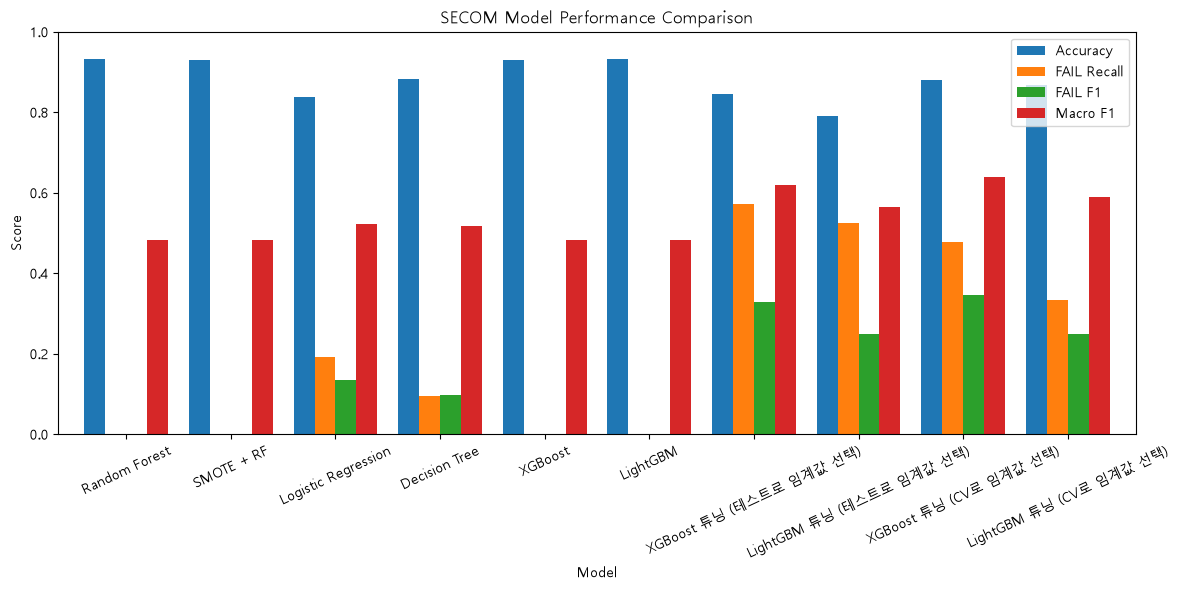

In [2]:

if not comparison_df.empty:
    metrics = [
        "Accuracy",
        "FAIL Recall",
        "FAIL F1",
        "Macro F1"
    ]

    plot_df = comparison_df.set_index("Model")[metrics]

    ax = plot_df.plot(
        kind="bar",
        figsize=(12, 6),
        ylim=(0, 1),
        width=0.8
    )

    ax.set_title("SECOM Model Performance Comparison")
    ax.set_ylabel("Score")
    ax.set_xlabel("Model")
    ax.tick_params(axis="x", rotation=25)
    ax.legend(loc="best")

    plt.tight_layout()
    plt.show()


In [3]:

for model_name, (y_true, y_pred) in predictions.items():
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    print(f"\n{model_name}")
    print("행: 실제값 / 열: 예측값")
    print("순서: PASS(0), FAIL(1)")
    display(
        pd.DataFrame(
            cm,
            index=["Actual PASS", "Actual FAIL"],
            columns=["Predicted PASS", "Predicted FAIL"]
        )
    )



Random Forest
행: 실제값 / 열: 예측값
순서: PASS(0), FAIL(1)


,Predicted PASS,Predicted FAIL
Actual PASS,293,0
Actual FAIL,21,0



SMOTE + RF
행: 실제값 / 열: 예측값
순서: PASS(0), FAIL(1)


,Predicted PASS,Predicted FAIL
Actual PASS,292,1
Actual FAIL,21,0



Logistic Regression
행: 실제값 / 열: 예측값
순서: PASS(0), FAIL(1)


,Predicted PASS,Predicted FAIL
Actual PASS,259,34
Actual FAIL,17,4


... (10 outputs left out)


XGBoost 튜닝 (CV로 임계값 선택)
행: 실제값 / 열: 예측값
순서: PASS(0), FAIL(1)


,Predicted PASS,Predicted FAIL
Actual PASS,266,27
Actual FAIL,11,10



LightGBM 튜닝 (CV로 임계값 선택)
행: 실제값 / 열: 예측값
순서: PASS(0), FAIL(1)


,Predicted PASS,Predicted FAIL
Actual PASS,265,28
Actual FAIL,14,7
